人口と民営従業員数の関連性

氏　名：長谷川 大祐
依頼元：企業の出店調査部門
読み手：出店候補地を検討する担当者

調べたい問い：年齢、業種別にも注目して比較し、都道府県別の人口と民営従業者数は、どのような関連があるのかを探る。

In [5]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import csv
import matplotlib.pyplot as plt

# Put japan.csv in the same folder as your notebook.
with open("japan.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))

print(len(data), "prefectures")
print(data[0]["Prefecture"], data[0]["総人口"])

47 prefectures
Hokkaido 5140000


１５歳未満、１５～６４歳、６５歳以上の３つで区切った県ごとの人口の総数を多い順で上から並べる。

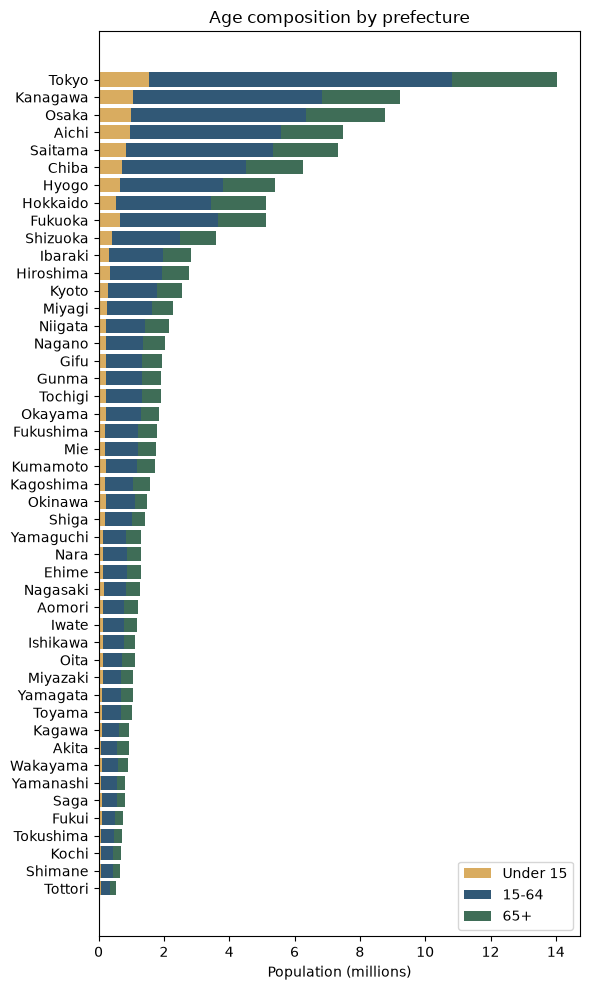

In [7]:
chosen = [row for row in data
          if row["Prefecture"] 
          in ["Hokkaido",
"Aomori",
"Iwate",
"Miyagi",
"Akita",
"Yamagata",
"Fukushima",
"Ibaraki",
"Tochigi",
"Gunma",
"Saitama",
"Chiba",
"Tokyo",
"Kanagawa",
"Niigata",
"Toyama",
"Ishikawa",
"Fukui",
"Yamanashi",
"Nagano",
"Gifu",
"Shizuoka",
"Aichi",
"Mie",
"Shiga",
"Kyoto",
"Osaka",
"Hyogo",
"Nara",
"Wakayama",
"Tottori",
"Shimane",
"Okayama",
"Hiroshima",
"Yamaguchi",
"Tokushima",
"Kagawa",
"Ehime",
"Kochi",
"Fukuoka",
"Saga",
"Nagasaki",
"Kumamoto",
"Oita",
"Miyazaki",
"Kagoshima",
"Okinawa"]]

def population_total(row):
    return (
        int(row["15歳未満人口"])
        + int(row["15～64歳人口"])
        + int(row["65歳以上人口"])
    )

chosen.sort(key=population_total, reverse=True)

names = [row["Prefecture"] for row in chosen]
young = [int(row["15歳未満人口"]) / 1_000_000 for row in chosen]
working = [int(row["15～64歳人口"]) / 1_000_000 for row in chosen]
older = [int(row["65歳以上人口"]) / 1_000_000 for row in chosen]
base = [young[i] + working[i] for i in range(len(chosen))]

plt.figure(figsize=(6,10))
plt.barh(names, young, label="Under 15", color="#d9ac60")
plt.barh(names, working, left=young, label="15-64", color="#315876")
plt.barh(names, older, left=base, label="65+", color="#3f6d57")

plt.gca().invert_yaxis()
plt.xlabel("Population (millions)")
plt.title("Age composition by prefecture")
plt.legend()
plt.tight_layout()
plt.show()

業種別に区切った県ごとの総民営従業員数を多い順で上から並べる。　上の人口のグラフと比較して人口と民営従業員の関連性について調べる。

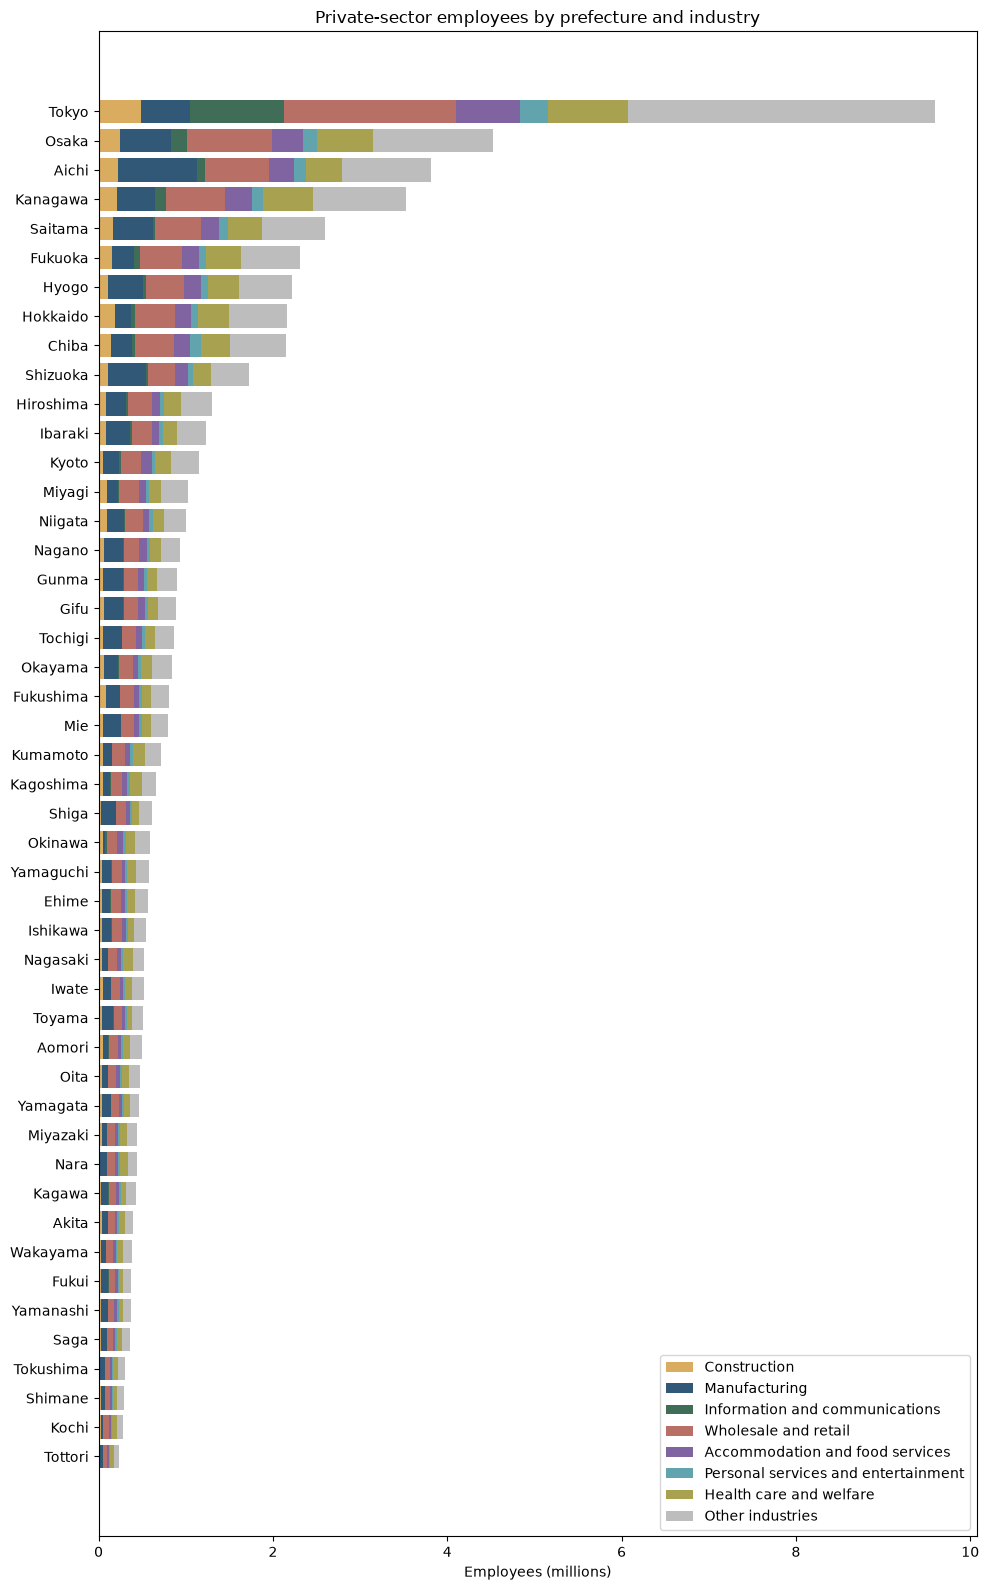

In [8]:
chosen = [row for row in data
          if row["Prefecture"] 
          in ["Hokkaido",
"Aomori",
"Iwate",
"Miyagi",
"Akita",
"Yamagata",
"Fukushima",
"Ibaraki",
"Tochigi",
"Gunma",
"Saitama",
"Chiba",
"Tokyo",
"Kanagawa",
"Niigata",
"Toyama",
"Ishikawa",
"Fukui",
"Yamanashi",
"Nagano",
"Gifu",
"Shizuoka",
"Aichi",
"Mie",
"Shiga",
"Kyoto",
"Osaka",
"Hyogo",
"Nara",
"Wakayama",
"Tottori",
"Shimane",
"Okayama",
"Hiroshima",
"Yamaguchi",
"Tokushima",
"Kagawa",
"Ehime",
"Kochi",
"Fukuoka",
"Saga",
"Nagasaki",
"Kumamoto",
"Oita",
"Miyazaki",
"Kagoshima",
"Okinawa"]]

def employee_total(row):
    return int(row["従業者数（民営）"])


chosen.sort(key=employee_total, reverse=True)

names = [row["Prefecture"] for row in chosen]
totals = [employee_total(row) / 1_000_000 for row in chosen]

industries = [
    ("建設業", "Construction", "#d9ac60"),
    ("製造業", "Manufacturing", "#315876"),
    ("情報通信業", "Information and communications", "#3f6d57"),
    ("卸売業、小売業", "Wholesale and retail", "#b86f65"),
    ("宿泊業、飲食サービス業", "Accommodation and food services", "#8064a2"),
    ("生活関連サービス業、娯楽業", "Personal services and entertainment", "#62a4ad"),
    ("医療、福祉", "Health care and welfare", "#a8a150"),
]

plt.figure(figsize=(10, 16))
left = [0] * len(chosen)

for industry, label, color in industries:
    column = "従業者数（民営）（" + industry + "）"
    values = [int(row[column]) / 1_000_000 for row in chosen]

    plt.barh(names, values, left=left, label=label, color=color)
    left = [left[i] + values[i] for i in range(len(chosen))]

other = [totals[i] - left[i] for i in range(len(chosen))]
plt.barh(names, other, left=left, label="Other industries", color="#bdbdbd")

plt.gca().invert_yaxis()
plt.xlabel("Employees (millions)")
plt.title("Private-sector employees by prefecture and industry")
plt.legend()
plt.tight_layout()
plt.show()

わかったこと


年齢別人口と民営従業者数のグラフを比較すると、人口が多い都道府県ほど、民営従業者数も同じ順位で多いとは限らないことが分かった。例えば、神奈川県は人口では２位だったが、民営従業者数では４位となり、大阪府と愛知県が上回っていた。

年齢別に見ると、神奈川県と大阪府は１５歳未満人口と６５歳以上人口がある程度似た値で、１５～６４歳人口は神奈川県の方が多かった。だが、民営従業者数は大阪府の方が多かった。この比較から、１５～６４歳人口が多い地域ほど民営従業者数も多いとは限らないことが分かった。



組織への提案


出店候補地を選ぶ際は、人口だけで判断せず民営従業者数や業種の内訳も合わせて確認することを提案する。
また、その県の業種の内訳の他にも、周辺の県の業種も踏まえて出店候補地を選ぶ方が良いと考える。